In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
sns.set(style='whitegrid')
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix,roc_auc_score,auc)
from sklearn.preprocessing import StandardScaler , LabelEncoder
from sklearn.naive_bayes import MultinomialNB
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(r"D:\Imarticus\ML\emerald_data.csv")
df

,unique_id,claim,gold_label,company,justification
0,0,EVgo and Amazon partner to enable voice-initia...,not_greenwashing,EVgo / Amazon,This is a factual statement describing the new...
1,1,"Amazon's Alexa now helps EV drivers find, navi...",not_greenwashing,Amazon,This is a factual description of the new featu...
2,2,Delta reduced its onboard single-use plastic c...,not_greenwashing,Delta,"This is a specific, quantifiable achievement d..."
3,3,"Delta announces a ""zero-waste flight"" as part ...",not_greenwashing,Delta,"The ""zero-waste flight"" was a specific, one-of..."
4,4,Delta is using more fuel-efficient A321neo air...,not_greenwashing,Delta,"This is a specific, verifiable improvement in ..."
...,...,...,...,...,...
615,615,Amazon commits to achieving net-zero carbon ac...,not_greenwashing,Amazon,"The article explicitly states that Amazon, thr..."
616,616,"Amazon plans to deploy 100,000 electric delive...",not_greenwashing,Amazon,The article clearly states Amazon's plan: '100...
617,617,Amazon has begun rolling out electric delivery...,not_greenwashing,Amazon,"The article states, 'Amazon’s electric deliver..."
618,618,Amazon has launched five electric Heavy Goods ...,not_greenwashing,Amazon,"The article explicitly states, 'earlier this y..."


In [3]:
df.head()

,unique_id,claim,gold_label,company,justification
0,0,EVgo and Amazon partner to enable voice-initia...,not_greenwashing,EVgo / Amazon,This is a factual statement describing the new...
1,1,"Amazon's Alexa now helps EV drivers find, navi...",not_greenwashing,Amazon,This is a factual description of the new featu...
2,2,Delta reduced its onboard single-use plastic c...,not_greenwashing,Delta,"This is a specific, quantifiable achievement d..."
3,3,"Delta announces a ""zero-waste flight"" as part ...",not_greenwashing,Delta,"The ""zero-waste flight"" was a specific, one-of..."
4,4,Delta is using more fuel-efficient A321neo air...,not_greenwashing,Delta,"This is a specific, verifiable improvement in ..."


In [4]:
df.tail()

,unique_id,claim,gold_label,company,justification
615,615,Amazon commits to achieving net-zero carbon ac...,not_greenwashing,Amazon,"The article explicitly states that Amazon, thr..."
616,616,"Amazon plans to deploy 100,000 electric delive...",not_greenwashing,Amazon,The article clearly states Amazon's plan: '100...
617,617,Amazon has begun rolling out electric delivery...,not_greenwashing,Amazon,"The article states, 'Amazon’s electric deliver..."
618,618,Amazon has launched five electric Heavy Goods ...,not_greenwashing,Amazon,"The article explicitly states, 'earlier this y..."
619,619,"Amazon's electric delivery vehicles, having ac...",greenwashing,Amazon,The article states the vehicles accumulated 'o...


In [5]:
df.sample()

,unique_id,claim,gold_label,company,justification
246,246,"Shop Amazon's ""Eco-Friendly"" products, now pow...",greenwashing,Amazon,The article discusses energy for Amazon's *ope...


In [6]:
df.shape

(620, 5)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 620 entries, 0 to 619
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   unique_id      620 non-null    int64 
 1   claim          620 non-null    object
 2   gold_label     620 non-null    object
 3   company        620 non-null    object
 4   justification  620 non-null    object
dtypes: int64(1), object(4)
memory usage: 24.3+ KB


In [8]:
df.describe()

,unique_id
count,620.000000
mean,309.500000
std,179.122863
min,0.000000
25%,154.750000
50%,309.500000
75%,464.250000
max,619.000000


In [9]:
df.describe(include="all")

,unique_id,claim,gold_label,company,justification
count,620.000000,620,620,620,620
unique,NaN,620,2,28,620
top,NaN,EVgo and Amazon partner to enable voice-initia...,not_greenwashing,Amazon,This is a factual statement describing the new...
freq,NaN,1,395,282,1
mean,309.500000,NaN,NaN,NaN,NaN
std,179.122863,NaN,NaN,NaN,NaN
min,0.000000,NaN,NaN,NaN,NaN
25%,154.750000,NaN,NaN,NaN,NaN
50%,309.500000,NaN,NaN,NaN,NaN
75%,464.250000,NaN,NaN,NaN,NaN


In [11]:
df.dtypes

unique_id         int64
claim            object
gold_label       object
company          object
justification    object
dtype: object

In [12]:
df.columns

Index(['unique_id', 'claim', 'gold_label', 'company', 'justification'], dtype='object')

In [13]:
df.isnull().sum()

unique_id        0
claim            0
gold_label       0
company          0
justification    0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.nunique()

unique_id        620
claim            620
gold_label         2
company           28
justification    620
dtype: int64

In [16]:
categorical = df.select_dtypes(include = 'object').columns

In [17]:
categorical

Index(['claim', 'gold_label', 'company', 'justification'], dtype='object')

In [19]:
numeric = df.select_dtypes(include = "number")
for col in numeric:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    outliers= outliers.shape[0]
    print(f"{col}:{outliers} ")

unique_id:0 


In [20]:
df['gold_label'].value_counts()

gold_label
not_greenwashing    395
greenwashing        225
Name: count, dtype: int64

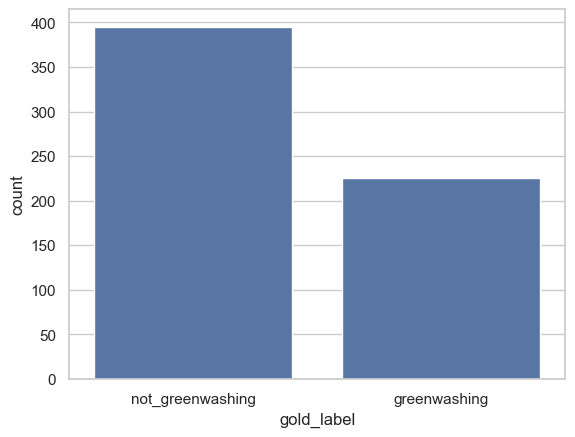

In [21]:
sns.countplot(x='gold_label',data = df)
plt.show()

In [22]:
label = LabelEncoder()
cat_cols = categorical
for col in cat_cols:
    df[col] = df[col].astype(str)
    df[col] = label.fit_transform(df[col])

In [23]:
x = df.drop(columns=['gold_label'])
y = df[['gold_label']]

In [24]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [25]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size= 0.2,random_state=42)

In [26]:
nb = MultinomialNB()

nb.fit(x_train, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [30]:
y_pred = nb.predict(x_test)

In [31]:
acc_score = accuracy_score(y_test,y_pred)
print("accuracy score:",acc_score)

accuracy score: 0.5564516129032258


In [28]:
# Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB
nb1 = GaussianNB()

nb1.fit(x_train, y_train)

,priors,None
,var_smoothing,1e-09


In [32]:
y_pred_nb1 = nb1.predict(x_test)

In [33]:
acc_score = accuracy_score(y_test,y_pred_nb1)
print("accuracy score:",acc_score)

accuracy score: 0.6451612903225806


In [29]:
# Bernoulli Naive Bayes
from sklearn.naive_bayes import BernoulliNB
nb2 = BernoulliNB()

nb2.fit(x_train, y_train)

,alpha,1.0
,force_alpha,True
,binarize,0.0
,fit_prior,True
,class_prior,None


In [34]:
y_pred_nb2 = nb2.predict(x_test)

In [35]:
acc_score = accuracy_score(y_test,y_pred_nb2)
print("accuracy score:",acc_score)

accuracy score: 0.6693548387096774


In [36]:
print("Training Accuracy",nb.score(x_train,y_train))
print("Testing Accuracy",nb.score(x_test,y_test))

Training Accuracy 0.5685483870967742
Testing Accuracy 0.5564516129032258


In [38]:
print("Training Accuracy",nb1.score(x_train,y_train))
print("Testing Accuracy",nb1.score(x_test,y_test))

Training Accuracy 0.6229838709677419
Testing Accuracy 0.6451612903225806


In [39]:
print("Training Accuracy",nb2.score(x_train,y_train))
print("Testing Accuracy",nb2.score(x_test,y_test))

Training Accuracy 0.6330645161290323
Testing Accuracy 0.6693548387096774
